# Slide 19: the KBM dataset, median extent ratio $\mathrm{Extent}_{\rm code}/\mathrm{Extent}_{\rm GS2}$ against WIDTH (TGLF top, GFTM bottom)

Fusion_PhD-qp5.32 (STEP GK talk, 2 Nov 2026). Replaces the $\gamma$-ratio figure (user: "the average extent ratio plots against fixed
widths for the KBM database"). Approach of `fig6_extent_vs_width_per_nbasis` (`tglf_quadrature_extent`, `gftm_quadrature_extent`), as a
signed ratio of one extent per mode instead of $|\log_{10}|$ per field.

- Population: GS2-KBM samples (user classifier) of the SPR-045 / M1 `kbm_8d` hypercubes, 119 / 161 (as slides 9 and 18).
- TGLF `TGLF/Runs/kbm_tglf_nbasis/<db>/nb<N>_nx32_fp2p0_<w>`: FILTER 2, NBASIS_MAX 8/16/32, NXGRID 32.
- GFTM (stock) `GFTM/Runs/LATIN_HYPERCUBE/<db>/kbm_8d/talk_f05_<w>_nb<N>_nx32`: FILTER 0.5, NBASIS_MAX 8/16/32, NXGRID 32.
- **Mode extent**: pyro's 95% rule (`Extent`) applied to $|\phi|^2 + |A_\parallel|^2$ in pyro's normalised fields, one extent per mode.
  $B_\parallel$ is left out for both codes (GFTM's is not trusted, so the two codes see the same fields).
- Per sample: dominant mode (argmax $\gamma$), ratio to GS2's mode extent; median over the samples where the code finds $\gamma > 0$
  (no mode, no extent: those samples are left out and counted below).


In [1]:
from pathlib import Path
import os
import warnings
from dotenv import load_dotenv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
# One style for every talk figure (identical in every notebook of this folder; Fusion_PhD-qp5.32). Each PNG fills the right-hand
# ~1060 x 800 px box of a 1920 x 1080 slide, so every figure is 10.6 x 8.0 in at 200 dpi and is saved at exactly that size
# (no bbox_inches="tight"): every PNG is scaled by the same factor on its slide, so text is the same size on every slide.
talk_style = {"figure.figsize": (10.6, 8.0), "savefig.dpi": 200, "savefig.bbox": "standard", "figure.constrained_layout.use": True,
              "font.size": 18, "axes.labelsize": 22, "axes.titlesize": 22, "figure.titlesize": 22,
              "xtick.labelsize": 18, "ytick.labelsize": 18, "legend.fontsize": 18, "lines.linewidth": 2.5, "lines.marker": "",
              "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"}
plt.rcParams.update(talk_style)
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
plots_dir = ROOT / "Plots" / "stepgk_20261102"
plots_dir.mkdir(parents=True, exist_ok=True)


def log_xticks(ax, ticks):
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.minorticks_off()
import json
from multiprocessing import get_context
import pandas as pd
from pyrokinetics import PyroHypercube
from pyrokinetics.pyroscan import PyroScanGKOutput
from pyrokinetics.diagnostics.extent import Extent
from general_analysis import mode_classification as mc

data_root = Path(os.environ["GK_DATA_ROOT"]).expanduser()
lhc = data_root / "GS2" / "Runs" / "LATIN_HYPERCUBE"
databases = ["SPR-045", "M1"]
fraction = 0.95
tglf_nbasis = [8, 16, 32]                    # NXGRID 32
gftm_nbasis = [8, 16, 32]                    # NXGRID 32, as TGLF (qp5.32)
gftm_root = Path(os.environ["GYRO_DATA_OUTPUT"])   # GyroRun wrote the talk_f05 leaves to the scratch tree
n_workers = int(os.environ.get("SLURM_CPUS_PER_TASK", 4))

In [2]:
def mode_extent(output):
    # pyro's 95% extent of |phi|^2 + |A_par|^2: one extent per mode
    power = output["eigenfunctions_squared"] if "eigenfunctions_squared" in output else np.abs(output["eigenfunctions"]) ** 2
    return Extent._compute(power.sel(field=["phi", "apar"]).sum("field"), fraction)[0].pint.dequantify()


gs2 = {}
for database in databases:
    gs2_dir = lhc / database / "kbm_8d"
    gs2_scan = mc.attach_legacy_funcs(PyroHypercube(pyroscan_json=gs2_dir / "pyro_cube" / "pyroscan.json", load_base_pyro=True))
    gs2_scan.load_gk_output(netcdf_file=gs2_dir / "pyro_cube" / "cube.nc")
    gs2_avg_scan = PyroHypercube(pyroscan_json=gs2_dir / "pyro_cube_avg" / "pyroscan.json", load_base_pyro=True)
    gs2_avg_scan.load_gk_output(netcdf_file=gs2_dir / "pyro_cube_avg" / "cube.nc")
    gamma_gs2 = gs2_avg_scan.gk_output.data.growth_rate.pint.dequantify().values.ravel()
    kbm = (np.asarray(mc.classify(mc.indicators(gs2_scan, gs2_scan.gk_output.data))) == "KBM") & np.isfinite(gamma_gs2) & (gamma_gs2 > 0)
    gs2_extent = mode_extent(gs2_scan.gk_output).transpose("sample", ...)
    print(database, "GS2-KBM:", kbm.sum(), "| GS2 extent dims", dict(gs2_extent.sizes))
    gs2[database] = dict(names=gs2_scan.gk_output.data.sample_name.values.astype(str)[kbm],
                         extent=gs2_extent.values.reshape(len(kbm), -1)[kbm, 0])
    print("   median GS2 mode extent (rad):", round(float(np.nanmedian(gs2[database]["extent"])), 3))


SPR-045 GS2-KBM: 119 | GS2 extent dims {'sample': 300}
   median GS2 mode extent (rad): 2.528


M1 GS2-KBM: 161 | GS2 extent dims {'sample': 300}
   median GS2 mode extent (rad): 2.655


In [3]:
def extent_ratios(output, database):
    data = output.data.assign(mode_extent=mode_extent(output)).set_index(sample="sample_name").sel(sample=gs2[database]["names"])
    growth = data.growth_rate.pint.dequantify().fillna(-np.inf).transpose("sample", "mode")
    mode = growth.argmax("mode")
    unstable = growth.isel(mode=mode).values > 0
    extent = data.mode_extent.transpose("sample", "mode").isel(mode=mode).values
    ratio = np.where(unstable, extent / gs2[database]["extent"], np.nan)
    return dict(extent_ratio=float(np.nanmedian(ratio)), n_found=int(unstable.sum()))


def load_tglf(leaf):
    tglf_scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    tglf_scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    flags = json.loads((leaf / "manifest.json").read_text())["code_flags"]
    assert float(flags["FILTER"]) == 2.0 and int(flags["NXGRID"]) == 32
    return dict(code="TGLF", database=leaf.parent.name, nbasis=int(flags["NBASIS_MAX"]),
                width=round(float(tglf_scan.base_pyro.gk_input.data["width"]), 4), **extent_ratios(tglf_scan.gk_output, leaf.parent.name))


def load_gftm(leaf):
    database = leaf.parent.parent.name
    gftm_scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    gftm_scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    flags = json.loads((leaf / "manifest.json").read_text())["code_flags"]
    assert float(flags["FILTER"]) == 0.5 and int(flags["NXGRID"]) == 32
    return dict(code="GFTM", database=database, nbasis=int(flags["NBASIS_MAX"]), width=round(float(flags["WIDTH"]), 4),
                **extent_ratios(gftm_scan.gk_output, database))


tglf_leaves = [leaf for database in databases for nbasis in tglf_nbasis
               for leaf in sorted((data_root / "TGLF" / "Runs" / "kbm_tglf_nbasis" / database).glob(f"nb{nbasis}_nx32_fp2p0_*"))]
gftm_leaves = [leaf for database in databases for nbasis in gftm_nbasis
               for leaf in sorted((gftm_root / "GFTM/Runs/LATIN_HYPERCUBE" / database / "kbm_8d").glob(f"talk_f05_w*_nb{nbasis}_nx32"))]
with get_context("fork").Pool(n_workers) as pool:
    medians = pd.DataFrame(pool.map(load_tglf, tglf_leaves, chunksize=2) + pool.map(load_gftm, gftm_leaves, chunksize=2)).sort_values(["code", "database", "nbasis", "width"])
print(medians.groupby(["code", "database", "nbasis"]).width.nunique().unstack().to_string())
print((medians.database.map({d: len(gs2[d]["names"]) for d in databases}) - medians.n_found).groupby([medians.code, medians.database, medians.nbasis]).max().unstack().to_string())  # samples with no unstable mode, max over WIDTH


nbasis         8   16  32
code database            
GFTM M1        24  24  24
     SPR-045   24  24  24
TGLF M1        24  24  24
     SPR-045   24  24  24
nbasis         8   16  32
code database            
GFTM M1         3   1   1
     SPR-045    5   1   2
TGLF M1         5   5   3
     SPR-045    8   6   6


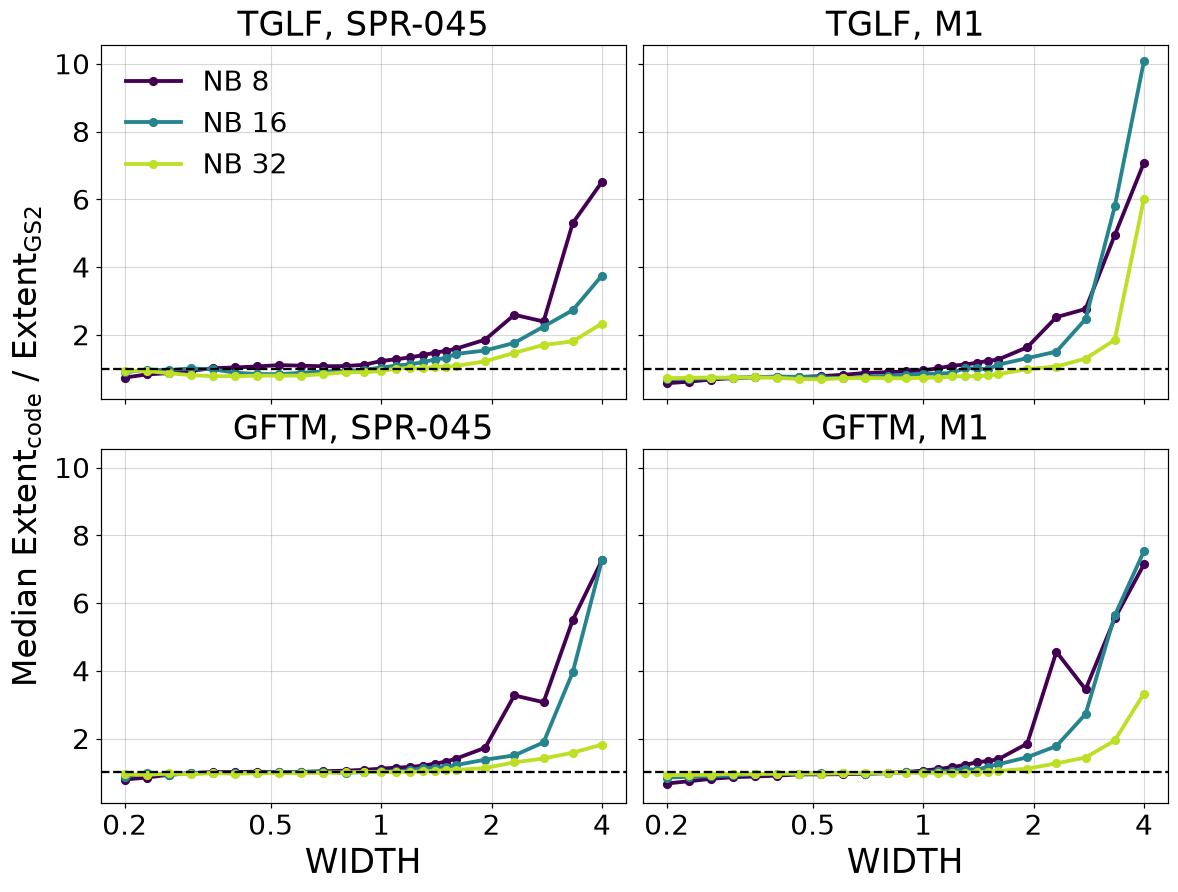

In [4]:
fig, axes = plt.subplots(2, 2, sharex=True, sharey=True)
for row, (code, nbasis_list) in enumerate((("TGLF", tglf_nbasis), ("GFTM", gftm_nbasis))):
    colours = dict(zip(nbasis_list, plt.cm.viridis(np.linspace(0, 0.9, len(nbasis_list)))))
    for ax, database in zip(axes[row], databases):
        for nbasis in nbasis_list:
            line = medians[(medians.code == code) & (medians.database == database) & (medians.nbasis == nbasis)]
            ax.plot(line.width, line.extent_ratio, color=colours[nbasis], marker="o", ms=5, label=f"NB {nbasis}")
        ax.axhline(1.0, color="k", ls="--", lw=1.5)
        ax.set(xscale="log", title=f"{code}, {database}")
        log_xticks(ax, [0.2, 0.5, 1, 2, 4])
axes[0, 0].legend()
fig.supylabel(r"Median Extent$_{\rm code}$ / Extent$_{\rm GS2}$")
for ax in axes[1]:
    ax.set_xlabel("WIDTH")
fig.savefig(plots_dir / "fig_slide19_dataset_extent_ratio.png")
plt.show()
